In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:

import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))


PyTorch version: 2.11.0+cu130
GPU available: True
GPU name: Tesla T4


In [3]:

!pip -q install transformers datasets accelerate evaluate pyyaml matplotlib


In [4]:

import transformers
import datasets
import accelerate

print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)
print("Accelerate:", accelerate.__version__)
print("Libraries installed successfully!")


Transformers: 5.20.2
Datasets: 4.8.5
Accelerate: 1.15.0
Libraries installed successfully!


In [5]:
from datasets import load_dataset

dataset = load_dataset("fancyzhx/ag_news", split="train[:1000]")

print(dataset[0])

README.md:   0%|          | 0.00/8.07k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

{'text': "Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\\band of ultra-cynics, are seeing green again.", 'label': 2}


In [6]:

# Check AG News dataset
print("Number of selected records:", len(dataset))
print("Columns:", dataset.column_names)

# Preview first 3 records
for i in range(3):
    print(f"\n--- Record {i+1} ---")
    print(dataset[i]["text"])


Number of selected records: 1000
Columns: ['text', 'label']

--- Record 1 ---
Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\band of ultra-cynics, are seeing green again.

--- Record 2 ---
Carlyle Looks Toward Commercial Aerospace (Reuters) Reuters - Private investment firm Carlyle Group,\which has a reputation for making well-timed and occasionally\controversial plays in the defense industry, has quietly placed\its bets on another part of the market.

--- Record 3 ---
Oil and Economy Cloud Stocks' Outlook (Reuters) Reuters - Soaring crude prices plus worries\about the economy and the outlook for earnings are expected to\hang over the stock market next week during the depth of the\summer doldrums.


In [7]:

import re
import pandas as pd

# Convert Hugging Face dataset to DataFrame
ag_df = dataset.to_pandas()

# Clean text
def clean_text(text):
    if not isinstance(text, str):
        return ""

    text = text.replace("\\", " ")
    text = re.sub(r"\s+", " ", text)
    return text.strip()

ag_df["text"] = ag_df["text"].apply(clean_text)

# Remove empty and duplicate records
ag_df = ag_df[ag_df["text"] != ""]
ag_df = ag_df.drop_duplicates(subset=["text"])

# Keep text only for CPT
ag_df = ag_df[["text"]].reset_index(drop=True)

print("Clean records:", len(ag_df))
print("\nFirst cleaned text:")
print(ag_df.iloc[0]["text"])


Clean records: 998

First cleaned text:
Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling band of ultra-cynics, are seeing green again.


In [8]:

from datasets import load_dataset

# Load 1000 movie reviews
imdb_dataset = load_dataset(
    "stanfordnlp/imdb",
    split="train[:1000]"
)

print("Number of records:", len(imdb_dataset))
print("Columns:", imdb_dataset.column_names)

print("\nFirst review:")
print(imdb_dataset[0]["text"][:500])


README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Number of records: 1000
Columns: ['text', 'label']

First review:
I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attent


In [9]:

import re
import html

# Convert IMDB dataset to DataFrame
imdb_df = imdb_dataset.to_pandas()

# Clean movie reviews
def clean_imdb_text(text):
    if not isinstance(text, str):
        return ""

    # Convert HTML line breaks to spaces
    text = re.sub(r"<br\s*/?>", " ", text, flags=re.IGNORECASE)

    # Remove remaining HTML tags
    text = re.sub(r"<[^>]+>", " ", text)

    # Decode HTML entities
    text = html.unescape(text)

    # Remove extra whitespace
    text = re.sub(r"\s+", " ", text)

    return text.strip()

# Apply cleaning
imdb_df["text"] = imdb_df["text"].apply(clean_imdb_text)

# Remove empty and duplicate reviews
imdb_df = imdb_df[imdb_df["text"] != ""]
imdb_df = imdb_df.drop_duplicates(subset=["text"])

# Keep text only
imdb_df = imdb_df[["text"]].reset_index(drop=True)

print("Clean IMDB records:", len(imdb_df))
print("\nFirst cleaned review:")
print(imdb_df.iloc[0]["text"][:500])


Clean IMDB records: 997

First cleaned review:
I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself. The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attentions to mak


In [10]:

from pathlib import Path

# Create a folder for cleaned CPT data
output_dir = Path("/kaggle/working/datascout_cpt")
output_dir.mkdir(parents=True, exist_ok=True)

# Save cleaned datasets
ag_df.to_csv(output_dir / "ag_news_clean.csv", index=False)
imdb_df.to_csv(output_dir / "imdb_clean.csv", index=False)

print("Files saved successfully!")

for file in output_dir.iterdir():
    print(file.name, "-", round(file.stat().st_size / 1024, 2), "KB")


Files saved successfully!
imdb_clean.csv - 1258.18 KB
ag_news_clean.csv - 245.11 KB


In [11]:

import pandas as pd
import zipfile
import io
import requests

url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

response = requests.get(url, timeout=60)
response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    print("Files inside ZIP:", z.namelist())

    with z.open("SMSSpamCollection") as f:
        sms_df = pd.read_csv(
            f,
            sep="\t",
            header=None,
            names=["label", "text"],
            encoding="utf-8"
        )

print("\nNumber of records:", len(sms_df))
print("\nFirst 3 records:")
print(sms_df.head(3))


Files inside ZIP: ['SMSSpamCollection', 'readme']

Number of records: 5572

First 3 records:
  label                                               text
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...


In [12]:

import re
from pathlib import Path

# Clean SMS messages
sms_df["text"] = sms_df["text"].apply(clean_text)

# Remove empty and duplicate messages
sms_df = sms_df[sms_df["text"] != ""]
sms_df = sms_df.drop_duplicates(subset=["text"])

# Keep text only
sms_df = sms_df[["text"]].reset_index(drop=True)

# Save cleaned data
output_dir = Path("/kaggle/working/datascout_cpt")
output_dir.mkdir(parents=True, exist_ok=True)

sms_df.to_csv(output_dir / "sms_spam_clean.csv", index=False)

print("Clean SMS records:", len(sms_df))
print("Saved successfully!")
print("\nFirst cleaned message:")
print(sms_df.iloc[0]["text"])


Clean SMS records: 5158
Saved successfully!

First cleaned message:
Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...


In [13]:

from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("openai-community/gpt2")

datasets_dict = {
    "AG News": ag_df,
    "IMDB": imdb_df,
    "SMS Spam": sms_df
}

total_tokens = 0

for name, df in datasets_dict.items():
    texts = df["text"].astype(str).tolist()

    token_counts = [
        len(tokenizer.encode(text, add_special_tokens=False))
        for text in texts
    ]

    count = sum(token_counts)
    total_tokens += count

    print(f"{name}: {len(texts)} records, {count:,} tokens")

print("\nTOTAL TOKENS:", f"{total_tokens:,}")
print("Approximate 512-token sequences:", total_tokens // 512)


config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1122 > 1024). Running this sequence through the model will result in indexing errors


AG News: 998 records, 53,682 tokens
IMDB: 997 records, 285,879 tokens
SMS Spam: 5158 records, 114,452 tokens

TOTAL TOKENS: 454,013
Approximate 512-token sequences: 886


In [15]:

from pathlib import Path
import pandas as pd

data_dir = Path("/kaggle/working/datascout_cpt")

files = [
    "ag_news_clean.csv",
    "imdb_clean.csv",
    "sms_spam_clean.csv"
]

for filename in files:
    path = data_dir / filename

    if path.exists():
        df = pd.read_csv(path)
        print(f"{filename}: {len(df)} records")
    else:
        print(f"MISSING: {filename}")


ag_news_clean.csv: 998 records
imdb_clean.csv: 997 records
sms_spam_clean.csv: 5158 records


In [19]:

from pathlib import Path
import json

input_dir = Path("/kaggle/input")
metadata_records = []

for file in input_dir.rglob("*.txt"):
    name = file.name.lower()

    if "meta" in name or "meatdata" in name:
        try:
            with open(file, "r", encoding="utf-8-sig") as f:
                data = json.load(f)

            metadata_records.append({
                "dataset": file.parent.name,
                "metadata": data
            })

            print("SUCCESS:", file.parent.name)

        except Exception as e:
            print("ERROR:", file.parent.name, "-", str(e))

print("\nTotal metadata loaded:", len(metadata_records))

if metadata_records:
    print("\nExample metadata:")
    print(json.dumps(
        metadata_records[0]["metadata"],
        indent=2,
        ensure_ascii=False
    )[:2000])



SUCCESS: SciFact
SUCCESS: arXiv Abstracts
SUCCESS: wikipedia natural
SUCCESS: IMDB dataset
SUCCESS: fake and real news
SUCCESS: sms spam collection
SUCCESS: AG-news
SUCCESS: ELI5
SUCCESS: SQuAD

Total metadata loaded: 9

Example metadata:
{
  "dataset_name": "SciFact - BEIR",
  "source": "Hugging Face - BeIR/scifact",
  "source_link": "https://huggingface.co/datasets/BeIR/scifact",
  "original_source": "AllenAI SciFact",
  "original_source_link": "https://github.com/allenai/scifact",
  "permissions_license": "The Hugging Face BEIR dataset card declares CC BY-SA 4.0. The original SciFact repository specifies CC BY 4.0 for claims and evidence annotations, and ODC-By 1.0 for abstracts from the S2ORC corpus. Follow the applicable license for each component and provide attribution.",
  "size": {
    "corpus_documents": 5183,
    "queries_or_claims": 1109,
    "relevance_judgments": 1258
  },
  "language": "English",
  "format": {
    "hugging_face": "Parquet",
    "original_beir": {
      "

In [18]:

from pathlib import Path

input_dir = Path("/kaggle/input")

for file in input_dir.rglob("*"):
    if file.is_file():
        print(file)


/kaggle/input/datasets/ohwaqar/datascoutai-data/datascoutai data/other datsets (1)/other datsets/SciFact/metadata.json.txt
/kaggle/input/datasets/ohwaqar/datascoutai-data/datascoutai data/other datsets (1)/other datsets/SciFact/samples.jsonl.txt
/kaggle/input/datasets/ohwaqar/datascoutai-data/datascoutai data/other datsets (1)/other datsets/arXiv Abstracts/metadat.json.txt
/kaggle/input/datasets/ohwaqar/datascoutai-data/datascoutai data/other datsets (1)/other datsets/arXiv Abstracts/samples.jsonl.txt
/kaggle/input/datasets/ohwaqar/datascoutai-data/datascoutai data/other datsets (1)/other datsets/wikipedia natural/meatdata.json.txt
/kaggle/input/datasets/ohwaqar/datascoutai-data/datascoutai data/other datsets (1)/other datsets/wikipedia natural/samples.jsonl.txt
/kaggle/input/datasets/ohwaqar/datascoutai-data/datascoutai data/kaggle datasets (1)/kaggle datasets/IMDB dataset/metadata.json.txt
/kaggle/input/datasets/ohwaqar/datascoutai-data/datascoutai data/kaggle datasets (1)/kaggle dat

In [20]:

import json
import pandas as pd
from pathlib import Path

metadata_texts = []

for record in metadata_records:
    dataset_name = record["dataset"]
    metadata = record["metadata"]

    # Convert metadata into readable text
    text = (
        f"Dataset: {dataset_name}\n"
        + json.dumps(
            metadata,
            ensure_ascii=False,
            indent=2
        )
    )

    metadata_texts.append({
        "dataset": dataset_name,
        "text": text
    })

metadata_df = pd.DataFrame(metadata_texts)

output_dir = Path("/kaggle/working/datascout_cpt")
metadata_df.to_csv(
    output_dir / "metadata_cpt.csv",
    index=False
)

print("Metadata documents:", len(metadata_df))
print("Saved successfully!")
print("\nFirst metadata text:")
print(metadata_df.iloc[0]["text"][:700])


Metadata documents: 9
Saved successfully!

First metadata text:
Dataset: SciFact
{
  "dataset_name": "SciFact - BEIR",
  "source": "Hugging Face - BeIR/scifact",
  "source_link": "https://huggingface.co/datasets/BeIR/scifact",
  "original_source": "AllenAI SciFact",
  "original_source_link": "https://github.com/allenai/scifact",
  "permissions_license": "The Hugging Face BEIR dataset card declares CC BY-SA 4.0. The original SciFact repository specifies CC BY 4.0 for claims and evidence annotations, and ODC-By 1.0 for abstracts from the S2ORC corpus. Follow the applicable license for each component and provide attribution.",
  "size": {
    "corpus_documents": 5183,
    "queries_or_claims": 1109,
    "relevance_judgments": 1258
  },
  "language": "English


In [21]:

import re
import pandas as pd
from pathlib import Path

output_dir = Path("/kaggle/working/datascout_cpt")

# Read the original cleaned SMS file
sms_df = pd.read_csv(output_dir / "sms_spam_clean.csv")

def anonymize_sms(text):
    text = str(text)

    # Replace email addresses
    text = re.sub(
        r'\b[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}\b',
        '[EMAIL]',
        text
    )

    # Replace website links
    text = re.sub(
        r'(?:https?://|www\.)\S+',
        '[URL]',
        text,
        flags=re.IGNORECASE
    )

    # Replace common phone number formats
    text = re.sub(
        r'(?<!\w)(?:\+?\d[\d\s().-]{6,}\d)(?!\w)',
        '[PHONE]',
        text
    )

    return text

sms_df["text"] = sms_df["text"].apply(anonymize_sms)

# Save a separate anonymized version
sms_df.to_csv(
    output_dir / "sms_spam_anonymized.csv",
    index=False
)

print("Anonymized SMS records:", len(sms_df))
print("Saved successfully!")

print("\nExample:")
print(sms_df.iloc[0]["text"])


Anonymized SMS records: 5158
Saved successfully!

Example:
Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...


In [22]:

import pandas as pd
from sklearn.model_selection import train_test_split
from pathlib import Path

output_dir = Path("/kaggle/working/datascout_cpt")

# Load cleaned text files
ag = pd.read_csv(output_dir / "ag_news_clean.csv")
imdb = pd.read_csv(output_dir / "imdb_clean.csv")
sms = pd.read_csv(output_dir / "sms_spam_anonymized.csv")
metadata = pd.read_csv(output_dir / "metadata_cpt.csv")

# Add dataset source labels
ag["source"] = "AG News"
imdb["source"] = "IMDB"
sms["source"] = "SMS Spam"

# Combine the text documents
corpus = pd.concat(
    [
        ag[["text", "source"]],
        imdb[["text", "source"]],
        sms[["text", "source"]]
    ],
    ignore_index=True
)

# Remove missing or empty text
corpus = corpus.dropna(subset=["text"])
corpus = corpus[corpus["text"].str.strip() != ""]

# Split documents into train and validation
train_df, val_df = train_test_split(
    corpus,
    test_size=0.10,
    random_state=42,
    shuffle=True
)

# Add all metadata documents to training
metadata["source"] = "Metadata"
train_df = pd.concat(
    [train_df, metadata[["text", "source"]]],
    ignore_index=True
)

# Save both splits
train_df.to_csv(output_dir / "cpt_train.csv", index=False)
val_df.to_csv(output_dir / "cpt_val.csv", index=False)

print("Training documents:", len(train_df))
print("Validation documents:", len(val_df))
print("Total documents:", len(train_df) + len(val_df))

print("\nTraining sources:")
print(train_df["source"].value_counts())

print("\nValidation sources:")
print(val_df["source"].value_counts())


Training documents: 6446
Validation documents: 716
Total documents: 7162

Training sources:
source
SMS Spam    4655
AG News      899
IMDB         883
Metadata       9
Name: count, dtype: int64

Validation sources:
source
SMS Spam    503
IMDB        114
AG News      99
Name: count, dtype: int64


In [23]:

from transformers import AutoTokenizer
import pandas as pd

tokenizer = AutoTokenizer.from_pretrained(
    "openai-community/gpt2"
)

train_df = pd.read_csv(
    "/kaggle/working/datascout_cpt/cpt_train.csv"
)
val_df = pd.read_csv(
    "/kaggle/working/datascout_cpt/cpt_val.csv"
)

BLOCK_SIZE = 512

def count_token_blocks(df):
    total_tokens = 0

    for text in df["text"].dropna():
        tokens = tokenizer.encode(
            str(text),
            add_special_tokens=False,
            verbose=False
        )
        total_tokens += len(tokens) + 1  # EOS separator

    full_blocks = total_tokens // BLOCK_SIZE
    remainder = total_tokens % BLOCK_SIZE

    return total_tokens, full_blocks, remainder

train_tokens, train_blocks, train_rem = count_token_blocks(train_df)
val_tokens, val_blocks, val_rem = count_token_blocks(val_df)

print("TRAIN")
print("Tokens:", f"{train_tokens:,}")
print("Full 512-token blocks:", train_blocks)
print("Remaining tokens:", train_rem)

print("\nVALIDATION")
print("Tokens:", f"{val_tokens:,}")
print("Full 512-token blocks:", val_blocks)
print("Remaining tokens:", val_rem)


TRAIN
Tokens: 413,654
Full 512-token blocks: 807
Remaining tokens: 470

VALIDATION
Tokens: 49,455
Full 512-token blocks: 96
Remaining tokens: 303


In [24]:

from datasets import Dataset
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(
    "openai-community/gpt2"
)

BLOCK_SIZE = 512

def create_blocks(df):
    all_tokens = []

    for text in df["text"].dropna():
        ids = tokenizer.encode(
            str(text),
            add_special_tokens=False,
            verbose=False
        )

        all_tokens.extend(ids)
        all_tokens.append(tokenizer.eos_token_id)

    blocks = []

    for i in range(0, len(all_tokens) - BLOCK_SIZE + 1, BLOCK_SIZE):
        block = all_tokens[i:i + BLOCK_SIZE]

        blocks.append({
            "input_ids": block,
            "attention_mask": [1] * BLOCK_SIZE,
            "labels": block.copy()
        })

    return Dataset.from_list(blocks)

train_dataset = create_blocks(train_df)
val_dataset = create_blocks(val_df)

print("Training blocks:", len(train_dataset))
print("Validation blocks:", len(val_dataset))

print("\nFirst training block length:",
      len(train_dataset[0]["input_ids"]))

print("First validation block length:",
      len(val_dataset[0]["input_ids"]))



Training blocks: 807
Validation blocks: 96

First training block length: 512
First validation block length: 512


In [25]:

import torch
from transformers import AutoModelForCausalLM

# Check GPU availability
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# Load original GPT-2 model
model = AutoModelForCausalLM.from_pretrained(
    "openai-community/gpt2"
)

model = model.to(device)
model.eval()

print("\nGPT-2 loaded successfully!")
print("Model parameters:",
      f"{model.num_parameters():,}")


Device: cuda
GPU: Tesla T4


model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]


GPT-2 loaded successfully!
Model parameters: 124,439,808


In [27]:

import torch
import math
from torch.utils.data import DataLoader

# Convert batches into PyTorch tensors
def collate_fn(examples):
    return {
        "input_ids": torch.tensor(
            [ex["input_ids"] for ex in examples],
            dtype=torch.long
        ),
        "attention_mask": torch.tensor(
            [ex["attention_mask"] for ex in examples],
            dtype=torch.long
        )
    }

val_loader = DataLoader(
    val_dataset,
    batch_size=2,
    shuffle=False,
    collate_fn=collate_fn
)

model.eval()

total_loss = 0.0
total_tokens = 0

with torch.no_grad():
    for batch in val_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=input_ids
        )

        predicted_tokens = input_ids.numel() - input_ids.size(0)

        total_loss += outputs.loss.item() * predicted_tokens
        total_tokens += predicted_tokens

baseline_loss = total_loss / total_tokens
baseline_ppl = math.exp(baseline_loss)

print("BASELINE RESULTS (Before CPT)")
print("-----------------------------")
print(f"Validation Loss: {baseline_loss:.4f}")
print(f"Perplexity: {baseline_ppl:.4f}")


  
       
       

[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


BASELINE RESULTS (Before CPT)
-----------------------------
Validation Loss: 4.2380
Perplexity: 69.2662


In [28]:

import json
import random
import numpy as np
import torch
from pathlib import Path

output_dir = Path("/kaggle/working/datascout_cpt")

# Training configuration
config = {
    "model_name": "openai-community/gpt2",
    "epochs": 2,
    "learning_rate": 5e-5,
    "batch_size": 2,
    "gradient_accumulation_steps": 4,
    "block_size": 512,
    "seed": 42
}

# Fix random seeds
random.seed(config["seed"])
np.random.seed(config["seed"])
torch.manual_seed(config["seed"])
torch.cuda.manual_seed_all(config["seed"])

# Save configuration
with open(output_dir / "cpt_config.json", "w") as f:
    json.dump(config, f, indent=2)

# Save baseline results
baseline_results = {
    "model": config["model_name"],
    "validation_loss_before_cpt": baseline_loss,
    "perplexity_before_cpt": baseline_ppl,
    "validation_blocks": len(val_dataset)
}

with open(output_dir / "baseline_results.json", "w") as f:
    json.dump(baseline_results, f, indent=2)

print("Configuration saved successfully!")
print("Baseline results saved successfully!")
print("\nTraining configuration:")
print(json.dumps(config, indent=2))


Configuration saved successfully!
Baseline results saved successfully!

Training configuration:
{
  "model_name": "openai-community/gpt2",
  "epochs": 2,
  "learning_rate": 5e-05,
  "batch_size": 2,
  "gradient_accumulation_steps": 4,
  "block_size": 512,
  "seed": 42
}


In [29]:

from torch.utils.data import DataLoader
import torch

# Create training DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size=config["batch_size"],
    shuffle=True,
    collate_fn=collate_fn
)

# Get one batch
batch = next(iter(train_loader))

input_ids = batch["input_ids"].to(device)
attention_mask = batch["attention_mask"].to(device)

print("Input shape:", input_ids.shape)
print("Attention mask shape:", attention_mask.shape)

# Test forward pass without updating model weights
model.eval()

with torch.no_grad():
    outputs = model(
        input_ids=input_ids,
        attention_mask=attention_mask,
        labels=input_ids
    )

print("Test batch loss:", round(outputs.loss.item(), 4))
print("GPU test successful!")


Input shape: torch.Size([2, 512])
Attention mask shape: torch.Size([2, 512])
Test batch loss: 4.0461
GPU test successful!


In [30]:

import re
import pandas as pd

sms_check = pd.read_csv(
    "/kaggle/working/datascout_cpt/sms_spam_anonymized.csv"
)

patterns = {
    "Possible emails": r"\b[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}\b",
    "Possible URLs": r"(?:https?://|www\.)\S+",
    "Possible phone numbers": r"(?<!\w)(?:\+?\d[\d\s().-]{6,}\d)(?!\w)"
}

for name, pattern in patterns.items():
    matches = sms_check["text"].astype(str).str.contains(
        pattern,
        regex=True,
        flags=re.IGNORECASE
    )
    print(f"{name}: {matches.sum()} possible matches")

print("\nPrivacy scan completed.")


Possible emails: 0 possible matches
Possible URLs: 0 possible matches
Possible phone numbers: 0 possible matches

Privacy scan completed.


In [31]:

import torch
import math
import json
from pathlib import Path
from torch.optim import AdamW

# Prepare output folder
output_dir = Path("/kaggle/working/datascout_cpt")
checkpoint_dir = output_dir / "checkpoint_epoch_1"

# Optimizer
optimizer = AdamW(
    model.parameters(),
    lr=config["learning_rate"]
)

accumulation_steps = config["gradient_accumulation_steps"]

# Start training
model.train()
optimizer.zero_grad()

total_train_loss = 0.0
total_train_tokens = 0

print("Starting CPT Epoch 1...")

for step, batch in enumerate(train_loader):
    input_ids = batch["input_ids"].to(device)
    attention_mask = batch["attention_mask"].to(device)

    outputs = model(
        input_ids=input_ids,
        attention_mask=attention_mask,
        labels=input_ids
    )

    loss = outputs.loss
    (loss / accumulation_steps).backward()

    predicted_tokens = input_ids.numel() - input_ids.size(0)
    total_train_loss += loss.item() * predicted_tokens
    total_train_tokens += predicted_tokens

    if (
        (step + 1) % accumulation_steps == 0
        or (step + 1) == len(train_loader)
    ):
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )
        optimizer.step()
        optimizer.zero_grad()

    if (step + 1) % 50 == 0:
        print(
            f"Step {step + 1}/{len(train_loader)} "
            f"| Loss: {loss.item():.4f}"
        )

train_loss_epoch1 = total_train_loss / total_train_tokens

print("\nEpoch 1 completed!")
print(f"Training Loss: {train_loss_epoch1:.4f}")

# Evaluate on validation data
model.eval()

total_val_loss = 0.0
total_val_tokens = 0

with torch.no_grad():
    for batch in val_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=input_ids
        )

        predicted_tokens = input_ids.numel() - input_ids.size(0)
        total_val_loss += outputs.loss.item() * predicted_tokens
        total_val_tokens += predicted_tokens

val_loss_epoch1 = total_val_loss / total_val_tokens
val_ppl_epoch1 = math.exp(val_loss_epoch1)

print("\nEPOCH 1 RESULTS")
print("------------------------")
print(f"Train Loss: {train_loss_epoch1:.4f}")
print(f"Validation Loss: {val_loss_epoch1:.4f}")
print(f"Validation Perplexity: {val_ppl_epoch1:.4f}")

print("\nBASELINE COMPARISON")
print(f"Before CPT PPL: {baseline_ppl:.4f}")
print(f"After Epoch 1 PPL: {val_ppl_epoch1:.4f}")

# Save checkpoint
checkpoint_dir.mkdir(parents=True, exist_ok=True)

model.save_pretrained(checkpoint_dir)
tokenizer.save_pretrained(checkpoint_dir)

results = {
    "epoch": 1,
    "train_loss": train_loss_epoch1,
    "validation_loss": val_loss_epoch1,
    "validation_perplexity": val_ppl_epoch1
}

with open(output_dir / "epoch1_results.json", "w") as f:
    json.dump(results, f, indent=2)

print("\nCheckpoint saved:", checkpoint_dir)


Starting CPT Epoch 1...
Step 50/404 | Loss: 4.2728
Step 100/404 | Loss: 4.1001
Step 150/404 | Loss: 4.4416
Step 200/404 | Loss: 3.9120
Step 250/404 | Loss: 4.0889
Step 300/404 | Loss: 4.1754
Step 350/404 | Loss: 4.4829
Step 400/404 | Loss: 3.8772

Epoch 1 completed!
Training Loss: 4.1653

EPOCH 1 RESULTS
------------------------
Train Loss: 4.1653
Validation Loss: 3.9513
Validation Perplexity: 52.0042

BASELINE COMPARISON
Before CPT PPL: 69.2662
After Epoch 1 PPL: 52.0042


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Checkpoint saved: /kaggle/working/datascout_cpt/checkpoint_epoch_1


In [33]:

from pathlib import Path
import shutil

checkpoint_dir = Path(
    "/kaggle/working/datascout_cpt/checkpoint_epoch_1"
)

archive_path = shutil.make_archive(
    "/kaggle/working/gpt2_cpt_epoch1",
    "zip",
    root_dir=checkpoint_dir
)

size_mb = Path(archive_path).stat().st_size / (1024 ** 2)

print("Checkpoint backup created!")
print("File:", archive_path)
print(f"Size: {size_mb:.2f} MB")


Checkpoint backup created!
File: /kaggle/working/gpt2_cpt_epoch1.zip
Size: 441.89 MB


In [35]:


from pathlib import Path

source = Path("/kaggle/working/gpt2_cpt_epoch1.zip")
chunk_size = 100 * 1024 * 1024

if not source.exists():
    print("ERROR: Checkpoint ZIP not found!")
else:
    with source.open("rb") as f:
        part = 1

        while True:
            data = f.read(chunk_size)

            if not data:
                break

            part_path = source.parent / f"gpt2_cpt_epoch1.part{part:02d}"
            part_path.write_bytes(data)

            print(
                f"Created: {part_path.name} "
                f"({len(data) / 1024**2:.1f} MB)"
            )

            part += 1

    print("\nAll parts created successfully!")


Created: gpt2_cpt_epoch1.part01 (100.0 MB)
Created: gpt2_cpt_epoch1.part02 (100.0 MB)
Created: gpt2_cpt_epoch1.part03 (100.0 MB)
Created: gpt2_cpt_epoch1.part04 (100.0 MB)
Created: gpt2_cpt_epoch1.part05 (41.9 MB)

All parts created successfully!


In [36]:

import torch
import math
import json
from pathlib import Path

output_dir = Path("/kaggle/working/datascout_cpt")
checkpoint_dir_2 = output_dir / "checkpoint_epoch_2"

model.train()
optimizer.zero_grad()

total_train_loss = 0.0
total_train_tokens = 0
accumulation_steps = config["gradient_accumulation_steps"]

print("Starting CPT Epoch 2...")

for step, batch in enumerate(train_loader):
    input_ids = batch["input_ids"].to(device)
    attention_mask = batch["attention_mask"].to(device)

    outputs = model(
        input_ids=input_ids,
        attention_mask=attention_mask,
        labels=input_ids
    )

    loss = outputs.loss
    (loss / accumulation_steps).backward()

    predicted_tokens = input_ids.numel() - input_ids.size(0)
    total_train_loss += loss.item() * predicted_tokens
    total_train_tokens += predicted_tokens

    if (
        (step + 1) % accumulation_steps == 0
        or (step + 1) == len(train_loader)
    ):
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )
        optimizer.step()
        optimizer.zero_grad()

    if (step + 1) % 50 == 0:
        print(
            f"Step {step + 1}/{len(train_loader)} "
            f"| Loss: {loss.item():.4f}"
        )

train_loss_epoch2 = total_train_loss / total_train_tokens

print("\nEpoch 2 completed!")
print(f"Training Loss: {train_loss_epoch2:.4f}")

# Validation
model.eval()

total_val_loss = 0.0
total_val_tokens = 0

with torch.no_grad():
    for batch in val_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=input_ids
        )

        predicted_tokens = input_ids.numel() - input_ids.size(0)
        total_val_loss += outputs.loss.item() * predicted_tokens
        total_val_tokens += predicted_tokens

val_loss_epoch2 = total_val_loss / total_val_tokens
val_ppl_epoch2 = math.exp(val_loss_epoch2)

print("\nEPOCH 2 RESULTS")
print("------------------------")
print(f"Train Loss: {train_loss_epoch2:.4f}")
print(f"Validation Loss: {val_loss_epoch2:.4f}")
print(f"Validation Perplexity: {val_ppl_epoch2:.4f}")

print("\nPERPLEXITY COMPARISON")
print(f"Before CPT: {baseline_ppl:.4f}")
print(f"After Epoch 1: {val_ppl_epoch1:.4f}")
print(f"After Epoch 2: {val_ppl_epoch2:.4f}")

# Save checkpoint
checkpoint_dir_2.mkdir(parents=True, exist_ok=True)

model.save_pretrained(checkpoint_dir_2)
tokenizer.save_pretrained(checkpoint_dir_2)

results = {
    "epoch": 2,
    "train_loss": train_loss_epoch2,
    "validation_loss": val_loss_epoch2,
    "validation_perplexity": val_ppl_epoch2
}

with open(output_dir / "epoch2_results.json", "w") as f:
    json.dump(results, f, indent=2)

print("\nCheckpoint saved:", checkpoint_dir_2)


Starting CPT Epoch 2...
Step 50/404 | Loss: 4.1647
Step 100/404 | Loss: 3.9091
Step 150/404 | Loss: 3.8800
Step 200/404 | Loss: 4.0146
Step 250/404 | Loss: 4.1368
Step 300/404 | Loss: 3.5732
Step 350/404 | Loss: 3.9718
Step 400/404 | Loss: 4.1205

Epoch 2 completed!
Training Loss: 3.9063

EPOCH 2 RESULTS
------------------------
Train Loss: 3.9063
Validation Loss: 3.9215
Validation Perplexity: 50.4783

PERPLEXITY COMPARISON
Before CPT: 69.2662
After Epoch 1: 52.0042
After Epoch 2: 50.4783


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Checkpoint saved: /kaggle/working/datascout_cpt/checkpoint_epoch_2


In [37]:

from pathlib import Path
import shutil
import zipfile

checkpoint_dir = Path(
    "/kaggle/working/datascout_cpt/checkpoint_epoch_2"
)

archive_path = shutil.make_archive(
    "/kaggle/working/gpt2_cpt_best",
    "zip",
    root_dir=checkpoint_dir
)

with zipfile.ZipFile(archive_path, "r") as z:
    bad_file = z.testzip()

print("Best checkpoint:", checkpoint_dir)
print("ZIP file:", archive_path)
print(
    "ZIP size:",
    round(Path(archive_path).stat().st_size / 1024**2, 2),
    "MB"
)
print(
    "ZIP integrity:",
    "OK" if bad_file is None else f"ERROR: {bad_file}"
)


Best checkpoint: /kaggle/working/datascout_cpt/checkpoint_epoch_2
ZIP file: /kaggle/working/gpt2_cpt_best.zip
ZIP size: 441.89 MB
ZIP integrity: OK


In [39]:

# Step 30: Prepare evaluation prompts

evaluation_prompts = [
    "A dataset for classifying news articles into categories is",
    
    "For sentiment analysis of movie reviews, a suitable dataset is",
    
    "A dataset for detecting spam text messages is",
    
    "For question answering tasks, researchers can use",
    
    "A dataset for scientific claim verification is"
]

print("Evaluation Prompts")
print("-" * 50)

for i, prompt in enumerate(evaluation_prompts, 1):
    print(f"{i}. {prompt}")

print("\nTotal prompts:", len(evaluation_prompts))


Evaluation Prompts
--------------------------------------------------
1. A dataset for classifying news articles into categories is
2. For sentiment analysis of movie reviews, a suitable dataset is
3. A dataset for detecting spam text messages is
4. For question answering tasks, researchers can use
5. A dataset for scientific claim verification is

Total prompts: 5


In [40]:

import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

# Load original GPT-2
base_model_name = "openai-community/gpt2"

base_tokenizer = AutoTokenizer.from_pretrained(base_model_name)

base_model = AutoModelForCausalLM.from_pretrained(
    base_model_name
).to(device)

base_model.eval()

# Generate baseline completions
baseline_completions = []

for i, prompt in enumerate(evaluation_prompts, 1):

    inputs = base_tokenizer(
        prompt,
        return_tensors="pt"
    ).to(device)

    with torch.no_grad():
        outputs = base_model.generate(
            **inputs,
            max_new_tokens=60,
            do_sample=False,
            pad_token_id=base_tokenizer.eos_token_id
        )

    # Decode only the generated continuation
    generated_tokens = outputs[0][inputs["input_ids"].shape[1]:]

    completion = base_tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True
    )

    baseline_completions.append(completion)

    print(f"\nPROMPT {i}: {prompt}")
    print(f"BEFORE CPT: {completion}")
    print("-" * 70)

print("\nAll 5 baseline completions generated!")


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]


PROMPT 1: A dataset for classifying news articles into categories is
BEFORE CPT:  available here.

The following table lists the categories of articles that are categorized as news articles.

News Articles Category Category Category Category Category Category Category Category Category Category Category Category Category Category Category Category Category Category Category Category Category Category Category Category Category Category Category Category Category Category Category Category Category Category Category Category
----------------------------------------------------------------------

PROMPT 2: For sentiment analysis of movie reviews, a suitable dataset is
BEFORE CPT:  the following:

The following table lists the reviews of the following films:

The following table lists the reviews of the following films:

The following table lists the reviews of the following films:

The following table lists the reviews of the following films:

The following table
-----------------------

In [41]:

# Step 32: Generate completions AFTER CPT

model.eval()

cpt_completions = []

for i, prompt in enumerate(evaluation_prompts, 1):

    inputs = tokenizer(
        prompt,
        return_tensors="pt"
    ).to(device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=60,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

    # Decode only the generated continuation
    generated_tokens = outputs[0][inputs["input_ids"].shape[1]:]

    completion = tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True
    )

    cpt_completions.append(completion)

    print(f"\nPROMPT {i}: {prompt}")
    print(f"AFTER CPT: {completion}")
    print("-" * 70)

print("\nAll 5 CPT completions generated!")



PROMPT 1: A dataset for classifying news articles into categories is
AFTER CPT:  available here.
----------------------------------------------------------------------

PROMPT 2: For sentiment analysis of movie reviews, a suitable dataset is
AFTER CPT:  the following: "The Hunger Games" (2004) - "The Hunger Games" (2004) - "The Hunger Games" (2004) - "The Hunger Games" (2004) - "The Hunger Games" (2004) - "The Hunger Games" (2004) - "The Hunger
----------------------------------------------------------------------

PROMPT 3: A dataset for detecting spam text messages is
AFTER CPT:  available here.
----------------------------------------------------------------------

PROMPT 4: For question answering tasks, researchers can use
AFTER CPT:  a computer program to search for answers.
----------------------------------------------------------------------

PROMPT 5: A dataset for scientific claim verification is
AFTER CPT:  available at the National Science Foundation's website.
-----------

In [42]:

import pandas as pd
from pathlib import Path

comparison_df = pd.DataFrame({
    "prompt": evaluation_prompts,
    "before_cpt": baseline_completions,
    "after_cpt": cpt_completions
})

output_path = Path(
    "/kaggle/working/datascout_cpt/"
    "cpt_prompt_comparison.csv"
)

comparison_df.to_csv(
    output_path,
    index=False,
    encoding="utf-8"
)

print("Comparison saved successfully!")
print("File:", output_path)
print("Number of prompts:", len(comparison_df))

display(comparison_df)


Comparison saved successfully!
File: /kaggle/working/datascout_cpt/cpt_prompt_comparison.csv
Number of prompts: 5


,prompt,before_cpt,after_cpt
0,A dataset for classifying news articles into c...,available here.\n\nThe following table lists ...,available here.
1,"For sentiment analysis of movie reviews, a sui...",the following:\n\nThe following table lists t...,"the following: ""The Hunger Games"" (2004) - ""T..."
2,A dataset for detecting spam text messages is,available here.\n\nThe following is a list of...,available here.
3,"For question answering tasks, researchers can use",a variety of tools to help them understand th...,a computer program to search for answers.
4,A dataset for scientific claim verification is,available at http://www.science.gov/data/data...,available at the National Science Foundation'...


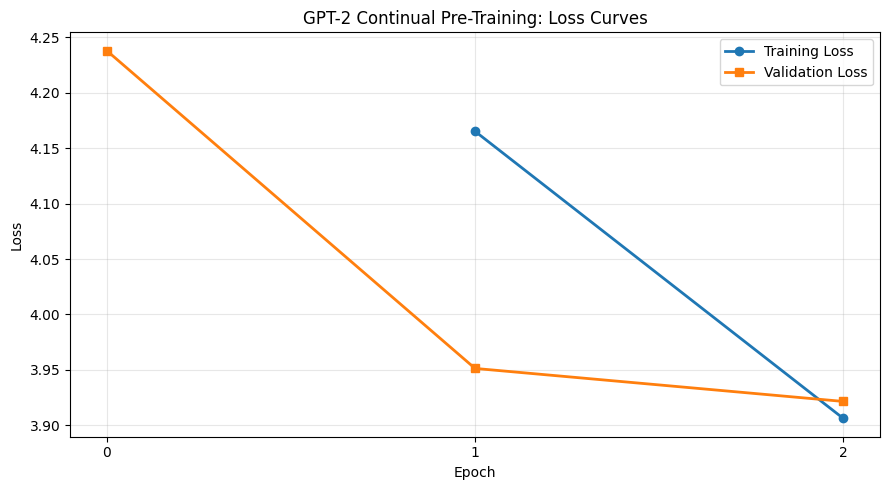

Loss curves saved successfully!
File: /kaggle/working/datascout_cpt/cpt_loss_curves.png


In [43]:

import matplotlib.pyplot as plt
from pathlib import Path

epochs = [1, 2]
train_losses = [train_loss_epoch1, train_loss_epoch2]

val_epochs = [0, 1, 2]
val_losses = [baseline_loss, val_loss_epoch1, val_loss_epoch2]

plt.figure(figsize=(9, 5))

plt.plot(
    epochs,
    train_losses,
    marker="o",
    linewidth=2,
    label="Training Loss"
)

plt.plot(
    val_epochs,
    val_losses,
    marker="s",
    linewidth=2,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GPT-2 Continual Pre-Training: Loss Curves")
plt.xticks([0, 1, 2])
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plot_path = Path(
    "/kaggle/working/datascout_cpt/"
    "cpt_loss_curves.png"
)

plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("Loss curves saved successfully!")
print("File:", plot_path)


In [45]:

from pathlib import Path
import yaml

output_dir = Path("/kaggle/working/datascout_cpt")

cpt_config = {
    "model": {
        "name": "openai-community/gpt2",
        "block_size": 512
    },
    "training": {
        "epochs": 2,
        "learning_rate": 5e-5,
        "batch_size": 2,
        "gradient_accumulation_steps": 4,
        "seed": 42
    },
    "data": {
        "train_file": "cpt_train.csv",
        "validation_file": "cpt_val.csv",
        "validation_split": 0.10
    },
    "output": {
        "best_checkpoint": "checkpoint_epoch_2"
    }
}

config_path = output_dir / "config.yaml"

with open(config_path, "w", encoding="utf-8") as f:
    yaml.safe_dump(
        cpt_config,
        f,
        sort_keys=False
    )

print("Config saved successfully!")
print("File:", config_path)

print("\nCONFIG CONTENT:")
print(config_path.read_text())


Config saved successfully!
File: /kaggle/working/datascout_cpt/config.yaml

CONFIG CONTENT:
model:
  name: openai-community/gpt2
  block_size: 512
training:
  epochs: 2
  learning_rate: 5.0e-05
  batch_size: 2
  gradient_accumulation_steps: 4
  seed: 42
data:
  train_file: cpt_train.csv
  validation_file: cpt_val.csv
  validation_split: 0.1
output:
  best_checkpoint: checkpoint_epoch_2



In [47]:

from pathlib import Path

output_dir = Path("/kaggle/working/datascout_cpt")

script = r'''
import json
import random
import math
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import yaml

from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForCausalLM
from torch.optim import AdamW


BASE_DIR = Path(__file__).resolve().parent

# Load configuration
with open(BASE_DIR / "config.yaml", "r") as f:
    config = yaml.safe_load(f)

MODEL_NAME = config["model"]["name"]
BLOCK_SIZE = config["model"]["block_size"]
EPOCHS = config["training"]["epochs"]
LR = config["training"]["learning_rate"]
BATCH_SIZE = config["training"]["batch_size"]
ACCUMULATION = config["training"]["gradient_accumulation_steps"]
SEED = config["training"]["seed"]

# Reproducibility
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Prepare token blocks
def create_blocks(csv_path):
    df = pd.read_csv(csv_path)
    all_tokens = []

    for text in df["text"].dropna():
        ids = tokenizer.encode(
            str(text),
            add_special_tokens=False,
            verbose=False
        )
        all_tokens.extend(ids)
        all_tokens.append(tokenizer.eos_token_id)

    blocks = []

    for i in range(
        0,
        len(all_tokens) - BLOCK_SIZE + 1,
        BLOCK_SIZE
    ):
        blocks.append(all_tokens[i:i + BLOCK_SIZE])

    return blocks


class CPTDataset(Dataset):
    def __init__(self, blocks):
        self.blocks = blocks

    def __len__(self):
        return len(self.blocks)

    def __getitem__(self, idx):
        ids = torch.tensor(
            self.blocks[idx],
            dtype=torch.long
        )
        return {
            "input_ids": ids,
            "attention_mask": torch.ones_like(ids)
        }


train_blocks = create_blocks(
    BASE_DIR / config["data"]["train_file"]
)

val_blocks = create_blocks(
    BASE_DIR / config["data"]["validation_file"]
)

train_dataset = CPTDataset(train_blocks)
val_dataset = CPTDataset(val_blocks)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training blocks:", len(train_dataset))
print("Validation blocks:", len(val_dataset))

# Load GPT-2
model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME
).to(device)

optimizer = AdamW(
    model.parameters(),
    lr=LR
)


def evaluate():
    model.eval()
    total_loss = 0.0
    total_tokens = 0

    with torch.no_grad():
        for batch in val_loader:
            ids = batch["input_ids"].to(device)
            mask = batch["attention_mask"].to(device)

            outputs = model(
                input_ids=ids,
                attention_mask=mask,
                labels=ids
            )

            tokens = ids.numel() - ids.size(0)
            total_loss += outputs.loss.item() * tokens
            total_tokens += tokens

    loss = total_loss / total_tokens
    return loss, math.exp(loss)


# Training
history = []
best_val_loss = float("inf")

for epoch in range(EPOCHS):
    model.train()
    optimizer.zero_grad()

    total_loss = 0.0
    total_tokens = 0

    for step, batch in enumerate(train_loader):
        ids = batch["input_ids"].to(device)
        mask = batch["attention_mask"].to(device)

        outputs = model(
            input_ids=ids,
            attention_mask=mask,
            labels=ids
        )

        loss = outputs.loss
        (loss / ACCUMULATION).backward()

        tokens = ids.numel() - ids.size(0)
        total_loss += loss.item() * tokens
        total_tokens += tokens

        if (
            (step + 1) % ACCUMULATION == 0
            or (step + 1) == len(train_loader)
        ):
            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )
            optimizer.step()
            optimizer.zero_grad()

    train_loss = total_loss / total_tokens
    val_loss, val_ppl = evaluate()

    result = {
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "validation_loss": val_loss,
        "validation_perplexity": val_ppl
    }

    history.append(result)

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Perplexity: {val_ppl:.4f}")

    checkpoint = BASE_DIR / f"checkpoint_epoch_{epoch + 1}"
    checkpoint.mkdir(exist_ok=True)

    model.save_pretrained(checkpoint)
    tokenizer.save_pretrained(checkpoint)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        model.save_pretrained(BASE_DIR / "best_checkpoint")
        tokenizer.save_pretrained(BASE_DIR / "best_checkpoint")

with open(BASE_DIR / "training_history.json", "w") as f:
    json.dump(history, f, indent=2)

print("\nTraining completed!")
print("Best validation loss:", best_val_loss)
'''

script_path = output_dir / "train_cpt.py"
script_path.write_text(script, encoding="utf-8")

# Check Python syntax without running training
compile(script, str(script_path), "exec")

print("train_cpt.py created successfully!")
print("Syntax check: PASSED")
print("File:", script_path)


train_cpt.py created successfully!
Syntax check: PASSED
File: /kaggle/working/datascout_cpt/train_cpt.py


In [49]:

import json
from pathlib import Path

output_dir = Path("/kaggle/working/datascout_cpt")

final_results = {
    "project": "DatasetScout AI",
    "phase": "Continued Pre-Training",
    "base_model": "GPT-2 Small",
    "gpu": "NVIDIA Tesla T4",

    "data": {
        "metadata_documents": 9,
        "training_documents": 6446,
        "validation_documents": 716,
        "sequence_length": 512,
        "training_blocks": 807,
        "validation_blocks": 96
    },

    "training": {
        "epochs": 2,
        "learning_rate": 0.00005,
        "batch_size": 2,
        "gradient_accumulation": 4
    },

    "results": {
        "baseline": {
            "validation_loss": 4.2380,
            "perplexity": 69.2662
        },
        "epoch_1": {
            "training_loss": 4.1653,
            "validation_loss": 3.9513,
            "perplexity": 52.0042
        },
        "epoch_2": {
            "training_loss": 3.9063,
            "validation_loss": 3.9215,
            "perplexity": 50.4783
        }
    },

    "best_checkpoint": "checkpoint_epoch_2",
    "perplexity_reduction_percent": 27.1
}

results_path = output_dir / "cpt_final_results.json"

with open(results_path, "w", encoding="utf-8") as f:
    json.dump(final_results, f, indent=4)

print("Final CPT results saved!")
print("File:", results_path)
print("\nBest Perplexity:", 50.4783)
print("Improvement: 27.1%")


Final CPT results saved!
File: /kaggle/working/datascout_cpt/cpt_final_results.json

Best Perplexity: 50.4783
Improvement: 27.1%


In [50]:

from pathlib import Path
import shutil

base = Path("/kaggle/working/datascout_cpt")

# Create handoff folder
handoff = Path("/kaggle/working/DatasetScout_CPT_Handoff")

if handoff.exists():
    shutil.rmtree(handoff)

handoff.mkdir(parents=True)

# Copy best model and tokenizer
shutil.copytree(
    base / "checkpoint_epoch_2",
    handoff / "best_checkpoint"
)

# Copy project files
files_to_copy = [
    "config.yaml",
    "cpt_final_results.json",
    "cpt_prompt_comparison.csv",
    "cpt_loss_curves.png",
    "train_cpt.py",
    "baseline_results.json",
    "cpt_config.json",
    "epoch1_results.json",
    "epoch2_results.json",
    "metadata_cpt.csv"
]

for filename in files_to_copy:
    source = base / filename

    if source.exists():
        shutil.copy2(source, handoff / filename)
        print("Copied:", filename)
    else:
        print("Not found:", filename)

# Create handoff instructions
readme = """
DatasetScout AI - CPT Handoff

Best checkpoint: best_checkpoint/
Base model: GPT-2 Small
Training: 2 epochs
Sequence length: 512
GPU: NVIDIA Tesla T4

Best validation loss: 3.9215
Best validation perplexity: 50.4783

The best_checkpoint directory contains the
fine-tuned GPT-2 weights and tokenizer files.

Use this checkpoint as the starting model
for the next SFT phase.

Do not load the original GPT-2 when starting SFT.
Load best_checkpoint instead.
"""

(handoff / "README.txt").write_text(
    readme,
    encoding="utf-8"
)

# Create ZIP
zip_path = shutil.make_archive(
    "/kaggle/working/DatasetScout_CPT_Handoff",
    "zip",
    root_dir=handoff.parent,
    base_dir=handoff.name
)

print("\nHANDOFF PACKAGE CREATED!")
print("Location:", zip_path)
print(
    "Size:",
    round(Path(zip_path).stat().st_size / 1024**2, 2),
    "MB"
)


Copied: config.yaml
Copied: cpt_final_results.json
Copied: cpt_prompt_comparison.csv
Copied: cpt_loss_curves.png
Copied: train_cpt.py
Copied: baseline_results.json
Copied: cpt_config.json
Copied: epoch1_results.json
Copied: epoch2_results.json
Copied: metadata_cpt.csv

HANDOFF PACKAGE CREATED!
Location: /kaggle/working/DatasetScout_CPT_Handoff.zip
Size: 442.01 MB


In [56]:

from pathlib import Path

base = Path("/kaggle/working/datascout_cpt")

for filename in ["cpt_train.csv", "cpt_val.csv"]:
    path = base / filename

    if path.exists():
        print(filename, "FOUND",
              round(path.stat().st_size / 1024, 2), "KB")
    else:
        print(filename, "NOT FOUND")


cpt_train.csv FOUND 1762.31 KB
cpt_val.csv FOUND 212.59 KB


In [57]:

from pathlib import Path
import shutil
import zipfile

base = Path("/kaggle/working/datascout_cpt")
handoff = Path("/kaggle/working/DatasetScout_CPT_Handoff")

# Add training and validation data
for filename in ["cpt_train.csv", "cpt_val.csv"]:
    shutil.copy2(base / filename, handoff / filename)
    print("Added:", filename)

# Recreate final ZIP
zip_path = Path(
    "/kaggle/working/DatasetScout_CPT_Handoff.zip"
)

if zip_path.exists():
    zip_path.unlink()

shutil.make_archive(
    str(zip_path.with_suffix("")),
    "zip",
    root_dir=handoff.parent,
    base_dir=handoff.name
)

# Verify ZIP integrity
with zipfile.ZipFile(zip_path, "r") as z:
    bad_file = z.testzip()
    files = z.namelist()

print("\nFINAL HANDOFF")
print("Files inside ZIP:", len(files))
print("ZIP integrity:", "OK" if bad_file is None else bad_file)
print("ZIP size:", round(zip_path.stat().st_size / 1024**2, 2), "MB")


Added: cpt_train.csv
Added: cpt_val.csv

FINAL HANDOFF
Files inside ZIP: 20
ZIP integrity: OK
ZIP size: 442.84 MB
